# Comparação das execuções de `oscillator1`

Este notebook reúne **todos os diretórios em `logs/` cujo nome começa com `oscillator1`**. Para cada execução, contabiliza amostras, scores válidos e ausentes, resume a distribuição dos scores, compara as melhores hipóteses registradas e mostra a referência física nos conjuntos `train`, `test_id` e `test_ood`.

## Como interpretar

O LLM-SR registra `score = -MSE` calculado durante a busca (em geral, no treino); portanto, score mais alto, mais próximo de zero, indica menor MSE nesse conjunto. Scores de execuções diferentes só são diretamente comparáveis se dados, configuração e protocolo de avaliação forem iguais. Os JSONs guardam código e score, mas não os parâmetros otimizados da hipótese; assim, este notebook não pode calcular os erros ID/OOD das candidatas. A equação física é calculada diretamente nos CSVs como referência.

Execute as células em ordem. A busca pelos logs é refeita a cada execução do notebook, então novas pastas `oscillator1*` serão incluídas automaticamente.


In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data/oscillator1").is_dir() and (candidate / "logs").is_dir():
            return candidate
    raise FileNotFoundError("Não encontrei a raiz do repositório LLM-SR. Abra o Jupyter dentro do repositório.")

ROOT = find_repo_root(Path.cwd().resolve())
LOGS_DIR = ROOT / "logs"
DATA_DIR = ROOT / "data" / "oscillator1"
RUN_DIRS = sorted(p for p in LOGS_DIR.iterdir() if p.is_dir() and p.name.startswith("oscillator1"))
print(f"Raiz: {ROOT}")
print(f"Diretórios oscillator1 encontrados: {len(RUN_DIRS)}")
for p in RUN_DIRS:
    print(" •", p.name)
if not RUN_DIRS:
    print("Nenhuma pasta logs/oscillator1* encontrada.")
plt.style.use("seaborn-v0_8-whitegrid")


Raiz: /home/ymws/Documentos/llm-sr/LLM-SR
Diretórios oscillator1 encontrados: 2
 • oscillator1_mistral_seed7_rag
 • oscillator1_qwen25


## 1. Leitura dos logs

In [2]:
records = []
read_errors = []
for run_dir in RUN_DIRS:
    sample_dir = run_dir / "samples"
    sample_paths = sorted(sample_dir.glob("samples_*.json")) if sample_dir.is_dir() else []
    for path in sample_paths:
        try:
            obj = json.loads(path.read_text(encoding="utf-8"))
            records.append({
                "execução": run_dir.name,
                "arquivo": path.name,
                "ordem": obj.get("sample_order"),
                "score": pd.to_numeric(obj.get("score"), errors="coerce"),
                "function": obj.get("function") or "",
            })
        except (OSError, json.JSONDecodeError) as exc:
            read_errors.append({"execução": run_dir.name, "arquivo": path.name, "erro": str(exc)})

samples = pd.DataFrame(records, columns=["execução", "arquivo", "ordem", "score", "function"])
if not samples.empty:
    samples["ordem"] = pd.to_numeric(samples["ordem"], errors="coerce")
    samples["score"] = pd.to_numeric(samples["score"], errors="coerce")
    samples["código presente"] = samples["function"].astype(str).str.strip().ne("")
print(f"Amostras lidas: {len(samples):,} | JSONs com erro: {len(read_errors):,}")
if read_errors:
    display(pd.DataFrame(read_errors).head(20))
display(samples.head())


Amostras lidas: 20,002 | JSONs com erro: 0


,execução,arquivo,ordem,score,function,código presente
0,oscillator1_mistral_seed7_rag,samples_0.json,0,-0.000419,"def equation(x: np.ndarray, v: np.ndarray, par...",True
1,oscillator1_mistral_seed7_rag,samples_10.json,10,NaN,"def equation(x: np.ndarray, v: np.ndarray, par...",True
2,oscillator1_mistral_seed7_rag,samples_100.json,100,NaN,"def equation(x: np.ndarray, v: np.ndarray, par...",True
3,oscillator1_mistral_seed7_rag,samples_1000.json,1000,-0.000413,"def equation(x: np.ndarray, v: np.ndarray, par...",True
4,oscillator1_mistral_seed7_rag,samples_10000.json,10000,NaN,"def equation(x: np.ndarray, v: np.ndarray, par...",True


## 2. Resumo comparativo por execução

In [3]:
if samples.empty:
    print("Não há amostras para resumir.")
else:
    run_summary = (samples.groupby("execução", dropna=False)
        .agg(amostras=("arquivo", "size"),
             scores_válidos=("score", "count"),
             scores_ausentes=("score", lambda s: int(s.isna().sum())),
             códigos_presentes=("código presente", "sum"),
             score_médio=("score", "mean"),
             score_mediano=("score", "median"),
             melhor_score=("score", "max"),
             pior_score=("score", "min"))
        .sort_values("melhor_score", ascending=False, na_position="last"))
    run_summary["% score válido"] = 100 * run_summary["scores_válidos"] / run_summary["amostras"]
    display(run_summary[["amostras", "scores_válidos", "scores_ausentes", "% score válido",
                         "score_médio", "score_mediano", "melhor_score", "pior_score"]].round(8))


,amostras,scores_válidos,scores_ausentes,% score válido,score_médio,score_mediano,melhor_score,pior_score
execução,,,,,,,,
oscillator1_mistral_seed7_rag,10001,3697,6304,36.966303,-1.318429e+21,-0.000418,-0.000000,-4.874232e+24
oscillator1_qwen25,10001,2434,7567,24.337566,-8.914468e+06,-0.000423,-0.000003,-2.160422e+10


## 3. Distribuição e evolução dos scores

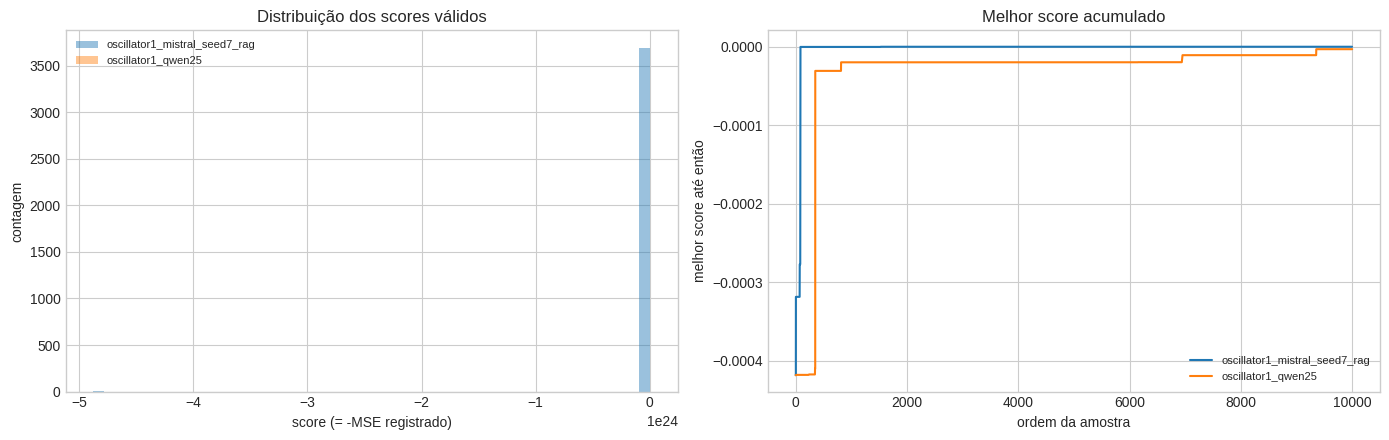

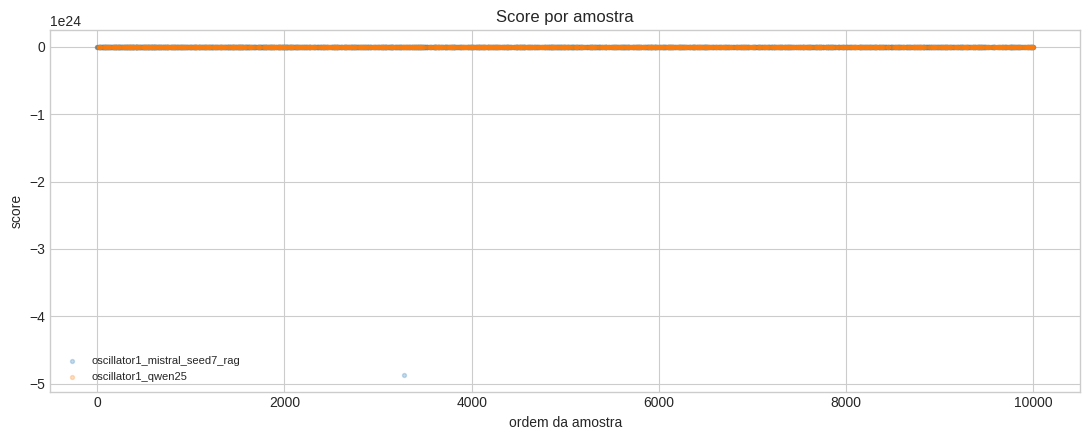

In [4]:
valid = samples.dropna(subset=["score"]).copy() if not samples.empty else pd.DataFrame()
if valid.empty:
    print("Nenhum score numérico encontrado.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for run_name, group in valid.groupby("execução"):
        axes[0].hist(group["score"], bins=50, alpha=.45, label=run_name)
        ordered = group.dropna(subset=["ordem"]).sort_values("ordem")
        if not ordered.empty:
            axes[1].plot(ordered["ordem"], ordered["score"].cummax(), label=run_name)
    axes[0].set(title="Distribuição dos scores válidos", xlabel="score (= -MSE registrado)", ylabel="contagem")
    axes[1].set(title="Melhor score acumulado", xlabel="ordem da amostra", ylabel="melhor score até então")
    for ax in axes:
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(11, 4.5))
    for run_name, group in valid.groupby("execução"):
        ordered = group.dropna(subset=["ordem"]).sort_values("ordem")
        ax.scatter(ordered["ordem"], ordered["score"], s=8, alpha=.25, label=run_name)
    ax.set(title="Score por amostra", xlabel="ordem da amostra", ylabel="score")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


## 4. Melhores hipóteses registradas

In [5]:
if valid.empty:
    print("Sem hipóteses com score válido.")
else:
    best_rows = (valid.sort_values(["execução", "score"], ascending=[True, False])
                 .groupby("execução", as_index=False).head(1)
                 .sort_values("score", ascending=False))
    display(best_rows[["execução", "ordem", "score", "arquivo"]].reset_index(drop=True))
    for _, row in best_rows.iterrows():
        print(f"\n{'=' * 90}\nExecução: {row['execução']} | amostra: {row['ordem']} | score: {row['score']:.10g} | {row['arquivo']}\n")
        print(row["function"])


,execução,ordem,score,arquivo
0,oscillator1_mistral_seed7_rag,9479,-2.141483e-10,samples_9479.json
1,oscillator1_qwen25,9352,-3.104526e-06,samples_9352.json



Execução: oscillator1_mistral_seed7_rag | amostra: 9479 | score: -2.14148312e-10 | samples_9479.json

def equation(x: np.ndarray, v: np.ndarray, params: np.ndarray) -> np.ndarray:
    """ Mathematical function for acceleration in a damped nonlinear oscillator

    Args:
        x: A numpy array representing observations of current position.
        v: A numpy array representing observations of velocity.
        params: Array of numeric constants or parameters to be optimized

    Return:
        A numpy array representing acceleration as the result of applying the mathematical function to the inputs.
    """
    """ Mathematical function for acceleration in a damped nonlinear oscillator
    
    Args:
        x: A numpy array representing observations of current position.
        v: A numpy array representing observations of velocity.
        params: Array of numeric constants or parameters to be optimized
    
    Return:
        A numpy array representing acceleration as the result 

## 5. Indícios estruturais dos termos verdadeiros

A tabela abaixo faz uma busca textual simples no código da melhor hipótese de cada execução. É um **indício**, não uma análise algébrica: formas equivalentes podem não ser reconhecidas e a presença de texto não garante que o termo contribua corretamente para a expressão.


In [6]:
def term_hints(source: str) -> dict[str, bool]:
    text = re.sub(r"\s+", "", str(source).lower())
    return {
        "sin(x)": bool(re.search(r"sin\([^)]*x[^)]*\)", text)),
        "v³": bool(re.search(r"v\*\*3|v\*v\*v|v\^3", text)),
        "x³": bool(re.search(r"x\*\*3|x\*x\*x|x\^3", text)),
        "x·v": bool(re.search(r"x\*v|v\*x", text)),
        "x·cos(x)": bool(re.search(r"x\*[^;\n]*cos\([^)]*x[^)]*\)|cos\([^)]*x[^)]*\)[^;\n]*\*x", text)),
    }

if not valid.empty:
    term_rows = []
    for _, row in best_rows.iterrows():
        term_rows.append({"execução": row["execução"], "ordem": row["ordem"], **term_hints(row["function"])})
    display(pd.DataFrame(term_rows).set_index("execução"))


,ordem,sin(x),v³,x³,x·v,x·cos(x)
execução,,,,,,
oscillator1_mistral_seed7_rag,9479,True,True,False,True,False
oscillator1_qwen25,9352,True,False,False,True,False


## 6. Referência física nos dados

In [7]:
TRUE_PARAMS = {"F": 0.8, "omega": 1.0, "alpha": 0.5, "beta": 0.2, "gamma": 0.5}
def oscillator1_ground_truth(x, v):
    p = TRUE_PARAMS
    return (p["F"] * np.sin(p["omega"] * x) - p["alpha"] * v**3
            - p["beta"] * x**3 - p["gamma"] * x * v - x * np.cos(x))

print("a = 0.8·sin(1.0·x) - 0.5·v³ - 0.2·x³ - 0.5·x·v - x·cos(x)")
truth_rows = []
for split in ["train", "test_id", "test_ood"]:
    df = pd.read_csv(DATA_DIR / f"{split}.csv")
    y = df["a"].to_numpy()
    pred = oscillator1_ground_truth(df["x"].to_numpy(), df["v"].to_numpy())
    mse = mean_squared_error(y, pred)
    truth_rows.append({"conjunto": split, "n": len(df), "MSE física": mse,
                       "RMSE física": np.sqrt(mse), "MAE física": mean_absolute_error(y, pred),
                       "R² física": r2_score(y, pred)})
truth_metrics = pd.DataFrame(truth_rows).set_index("conjunto")
display(truth_metrics)


a = 0.8·sin(1.0·x) - 0.5·v³ - 0.2·x³ - 0.5·x·v - x·cos(x)


,n,MSE física,RMSE física,MAE física,R² física
conjunto,,,,,
train,10000,5.802711e-34,2.408882e-17,1.594241e-17,1.0
test_id,10000,5.580930e-34,2.362399e-17,1.586220e-17,1.0
test_ood,10000,3.923944e-33,6.264139e-17,4.018182e-17,1.0


## Leitura final

Use `melhor_score` para identificar a hipótese com menor MSE de treino **entre os scores registrados** (desde que as execuções sejam comparáveis). A referência física deve ter erro numérico próximo de zero nos CSVs se os dados e os parâmetros correspondem à equação documentada. A tabela estrutural ajuda a ver quais termos aparecem textualmente nas melhores hipóteses.

Os scores `None` representam tentativas que não receberam pontuação válida e entram nas contagens, não no ranking. Este notebook não executa o código gerado pelas candidatas e não calcula seus erros `test_id`/`test_ood`, porque os parâmetros ajustados não estão nos arquivos JSON. Para essa comparação, seria preciso salvar os parâmetros durante a busca ou reajustar explicitamente cada esqueleto no treino e então avaliá-lo sem reajuste nos testes.
